# Exploratory Data Analysis

## Introduction

This notebook presents the Exploratory Data Analysis (EDA) for the PlaySafe project.

The purpose of this analysis is to obtain a basic understanding of the cleaned LaLiga player dataset before developing the final model of the porject.

The analysis focuses on the main characteristics of the dataset, the distribution of relevant variables, and the remaining missing values.

The findings from this analysis will be used to support the preparation of the dataset for the final model.

The raww dataset was found in a GitHub repository(https://github.com/Michael-starz/football-injury-scraper/blob/main/laliga_players.csv?)

##  Dataset Overview

The first step of the analysis is to inspect the cleaned dataset and understand its general structure. This includes checking the number of rows and columns, reviewing the available variables and examining a small sample of the data.

This initial inspection provides an overview of the dataset before analysing the individual variables and their relationships with injury information.


In [1]:
import pandas as pd
import numpy as np

# Load the cleaned dataset
df = pd.read_csv("../data/processed/laliga_cleaned.csv")

print("Shape:", df.shape)
df.head()

Shape: (3713, 14)


,player_name,date_of_birth_age,height,position,current_age_x,minutes_played,season,injury,from_date,to_date,days_out,matches_missed,injury_year,age_at_injury
0,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,2970.0,24/25,Adductor injury,2024-10-23,2024-11-23,32.0,3.0,2024.0,31.0
1,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,2970.0,24/25,Adductor tear,2024-09-30,2024-10-18,19.0,2.0,2024.0,31.0
2,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,513.0,23/24,Meniscus tear,2024-03-19,2024-04-28,41.0,6.0,2024.0,31.0
3,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,513.0,23/24,Cruciate ligament tear,2023-08-10,2024-03-31,235.0,42.0,2023.0,30.0
4,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,4920.0,22/23,Adductor pain,2023-03-26,2023-03-30,5.0,1.0,2023.0,30.0


Before analysing individual variables, the structure of the cleaned dataset is inspected. This includes the number of records, the number of unique players, and the number of records associated with each player.

This is important because the dataset can contain multiple records for the same player, as a player may have multiple injury records across different seasons.

In [2]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Number of unique players:", df["player_name"].nunique())

Number of rows: 3713
Number of columns: 14
Number of unique players: 490


In [3]:
df["player_name"].value_counts().head(10)
#how many records exist for each player

player_name
Juan Cruz                40
David Alaba              22
Andreas Christensen      22
JosÃ© MarÃ­a GimÃ©nez    22
William Carvalho         22
Antonio RÃ¼diger         21
Viktor Tsygankov         21
Daniel Carvajal          20
Ricardo RodrÃ­guez       20
Giovani Lo Celso         20
Name: count, dtype: int64

In [4]:
player_season_counts = (
    df.groupby(["player_name", "season"])
      .size()
      .sort_values(ascending=False)
)
#count how many records exist for each player in each season, sorted by the number of records
player_season_counts.head(10)

player_name       season
Juan Cruz         22/23     8
                  23/24     8
David Alaba       21/22     8
Antonio RÃ¼diger  18/19     6
Marc Bartra       16/17     6
Viktor Tsygankov  20/21     6
Nico Williams     23/24     6
Arsen Zakharyan   23/24     5
Marcos Llorente   21/22     5
Matija NastasiÄ‡  17/18     5
dtype: int64

The results show that multiple records can exist for the same player and season. This indicates that the dataset is based on individual records so each row represents a recorded entry for a player, rather than one record per player-season. Therefore, repeated player records should not be removed as duplicates at this stage


The data types and number of non-null values are inspected to identify the structure of the variables and the presence of missing values

In [5]:
df.info()
#display basic information about the DataFrame

<class 'pandas.DataFrame'>
RangeIndex: 3713 entries, 0 to 3712
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   player_name        3713 non-null   str    
 1   date_of_birth_age  3713 non-null   str    
 2   height             3696 non-null   float64
 3   position           3713 non-null   str    
 4   current_age_x      3713 non-null   int64  
 5   minutes_played     3704 non-null   float64
 6   season             3704 non-null   str    
 7   injury             1776 non-null   str    
 8   from_date          1776 non-null   str    
 9   to_date            1774 non-null   str    
 10  days_out           1776 non-null   float64
 11  matches_missed     1676 non-null   float64
 12  injury_year        1776 non-null   float64
 13  age_at_injury      1776 non-null   float64
dtypes: float64(6), int64(1), str(7)
memory usage: 638.0 KB


The number of missing values in each variable is examined to identify where missing data is concentrated in the dataset.

In [6]:
df.isna().sum().sort_values(ascending=False)
#calculates the total number of missing value per column

matches_missed       2037
to_date              1939
injury               1937
from_date            1937
days_out             1937
injury_year          1937
age_at_injury        1937
height                 17
minutes_played          9
season                  9
current_age_x           0
position                0
player_name             0
date_of_birth_age       0
dtype: int64

The missing values are mainly concentrated in the injury-related variables. The variables injury, from_date, days_out, injury_year, and age_at_injury each have 1,937 missing values, while to_date has 1,939 and matches_missed has 2,037. Only a small number of values are missing for height, minutes_played, and season.

The main categorical variables, position and season, are examined to understand their distribution within the dataset.

In [7]:
print("Positions:")
print(df["position"].value_counts())
#calculates total number of records for each position
print("\nSeasons:")
print(df["season"].value_counts().sort_index())

Positions:
position
Centre-Back           731
Central Midfield      451
Centre-Forward        423
Goalkeeper            360
Right-Back            346
Right Winger          305
Left Winger           302
Defensive Midfield    278
Left-Back             268
Attacking Midfield    208
Right Midfield         25
Second Striker         16
Name: count, dtype: int64

Seasons:
season
12/13     84
13/14    119
14/15    158
15/16    185
16/17    227
17/18    291
18/19    331
19/20    319
20/21    438
21/22    444
22/23    427
23/24    431
24/25    250
Name: count, dtype: int64


The dataset contains 12 different player positions. Centre-Back is the most represented position, followed by Central Midfield and Centre-Forward.

The dataset covers 13 seasons, from 12/13 to 24/25. The number of records differs between seasons, with the highest number of records in the 20/21 and 21/22 seasons.

These differences in the number of records across positions and seasons should be considered when preparing the data

## Univariate charts

 This is a type of data visualization where we visualize only a single variable at a time.

This chart shows us which positions are most frequented in the dataset.
This displays the number of records per position, not the number of unique players.  

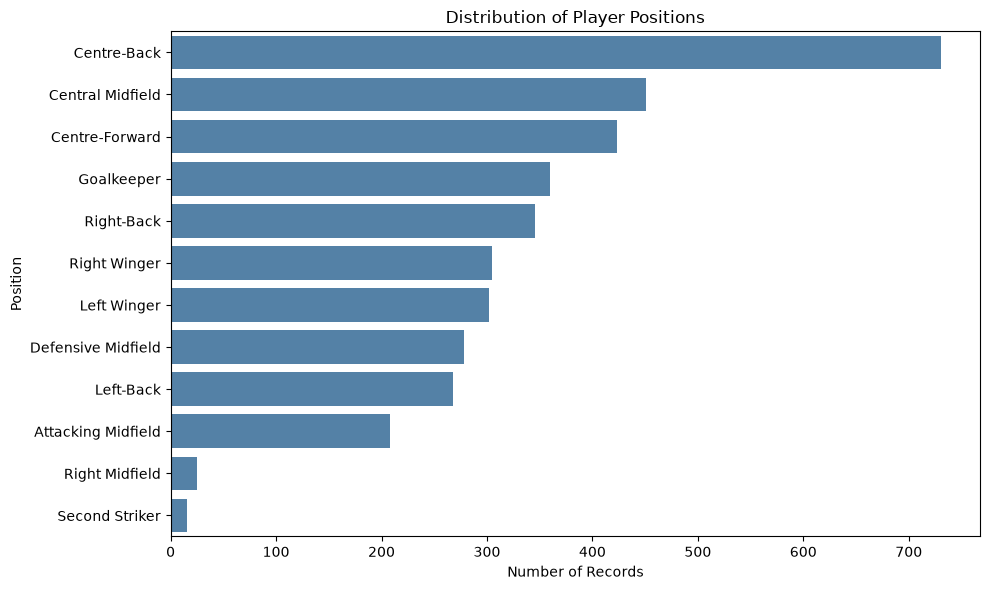

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="position",
    order=df["position"].value_counts().index,
    color="steelblue"
)

plt.title("Distribution of Player Positions")
plt.xlabel("Number of Records")
plt.ylabel("Position")

plt.tight_layout()
plt.show()

Whith this diagram, we can observe the different records of each position, being the second-striker the less recurrent position and the centre-back the most recurrent with more than 700 records. This help us to have a clear view of how the dataset is distributed.

This chart helps us visualise how the number of records change across seasons


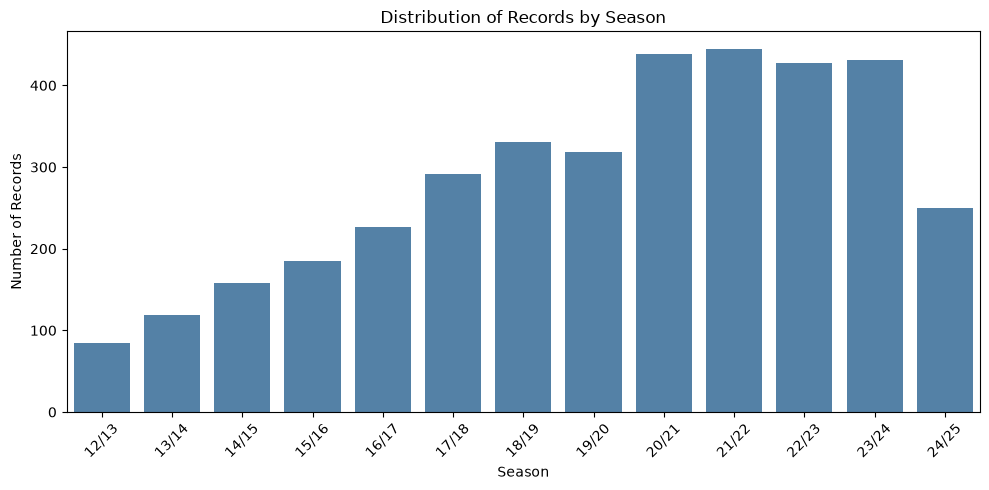

In [9]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="season",
    order=sorted(df["season"].dropna().unique()),
    color="steelblue"
)

plt.title("Distribution of Records by Season")
plt.xlabel("Season")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The results help us to have a clear view of which seasons have more records and which ones not. The seasons 20-21 and 21-22 are the largest seasons while the 12-13 is the one that has less records with less tan 100.

## Bivariate charts

This is a statistical method used to explore the relationship between two variables. The goal is to understand whether and how the two variables are related and describe their relationship.

For the first chart, I will analyse the relationship between the age and the days out of an injury. This allows us to investigate whether older players tend to experience longer injury absences

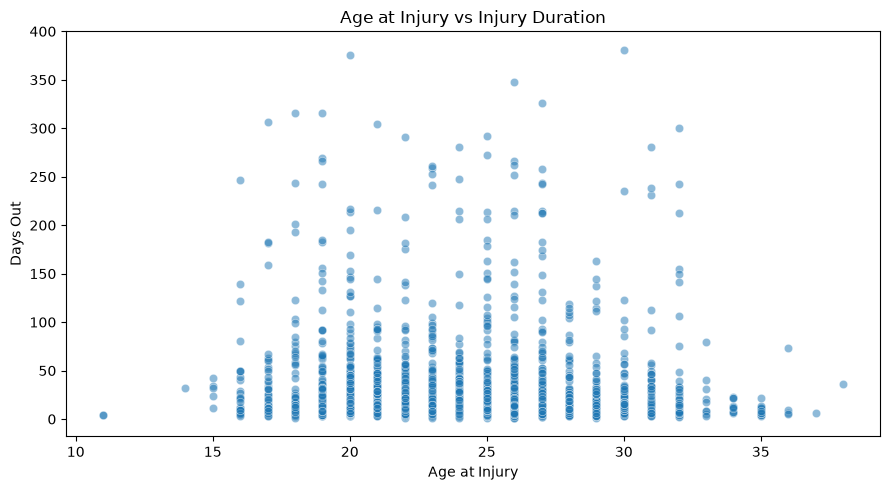

In [10]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="age_at_injury",
    y="days_out",
    alpha=0.5
)

plt.title("Age at Injury vs Injury Duration")
plt.xlabel("Age at Injury")
plt.ylabel("Days Out")

plt.tight_layout()
plt.show()

We can observe most of the injuries take place between 20 and 30 years aproximately and usually dont take longer than 100 days out. However, there are some cases in which it can take longer, the largest one was almost of 400 days of abscense. 
This also show us there is no direct relationship of the oldest you are, the more number and longest injuries you have.

Now we will display the relationship the position of a player and the numbers of days out have. With this we can see if different playing positions may show different distributions of injury duration

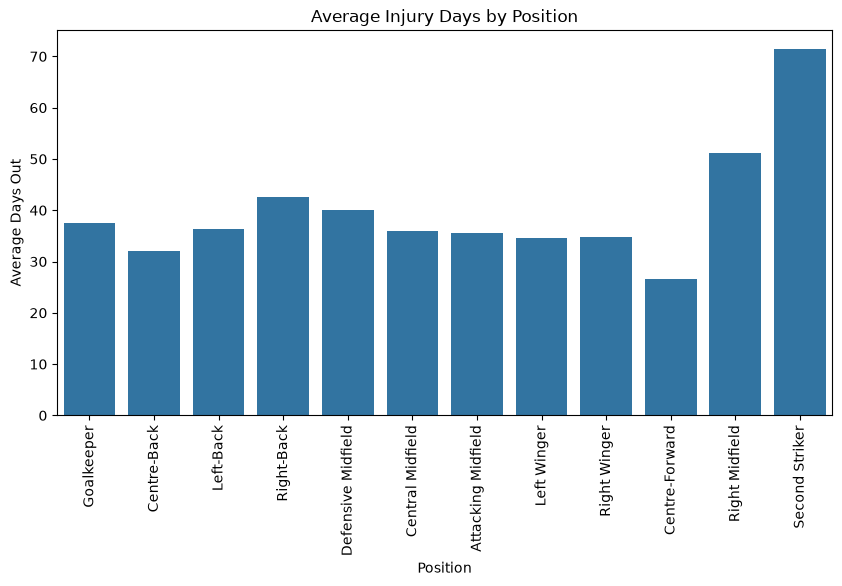

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="position", y="days_out", errorbar=None)

plt.xticks(rotation=90)
plt.title("Average Injury Days by Position")
plt.xlabel("Position")
plt.ylabel("Average Days Out")

plt.show()

With this results, we can see that the second-striker ( which was the one we saw few charts ago that had the less numbers of records) is the one who has a longer average of days out in an injury. On the other hand, the Centre-Forward is the position with less days out.

With the next chart We want to explore whether players who play more minutes tend to spend more days injured so we will anylise the relationship between days out and minutes played

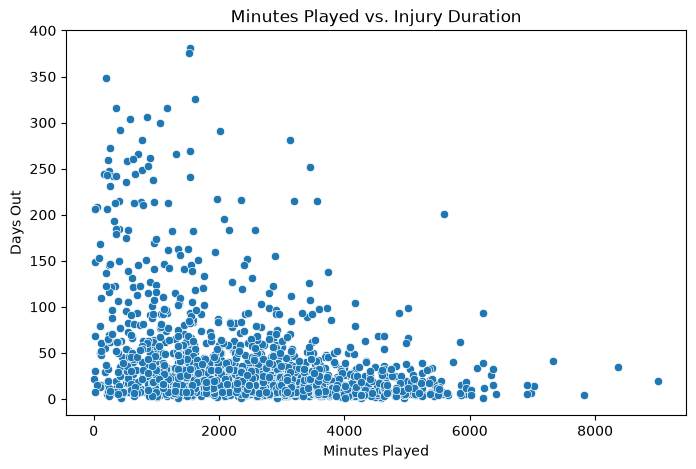

In [12]:

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="minutes_played", y="days_out")

plt.title("Minutes Played vs. Injury Duration")
plt.xlabel("Minutes Played")
plt.ylabel("Days Out")

plt.show()


The scatter plot shows no clear relationship between minutes played and injury duration.
Most recorded injuries lasted fewer than 100 days, across a wide range of playing time so we can not make any conclusions about the relationship between playing time and injury duration.

## Conclusion 

The exploratory data analysis revealed several important characteristics of the LaLiga dataset. The dataset contains 3,713 records corresponding to 490 unique players, with multiple records for some players within the same season. The dataset covers 13 seasons, from 2012/13 to 2024/25, although the number of records varies across seasons. Centre-Back is the most represented position, while Second Striker is the least represented.

The analysis of missing values showed that most missing data is concentrated in injury-related variables, including injury type, injury dates and days out. This is an important limitation because missing injury information cannot automatically be interpreted as evidence that a player did not suffer an injury.

The visualisations also revealed differences in injury duration across playing positions. Second Striker had the highest average injury duration, despite having the fewest records, while Centre-Forward had the lowest average. However, these results should be interpreted cautiously because positions with fewer records may have less representative averages.

The scatter plots showed that most recorded injuries lasted fewer than 100 days, although some injuries lasted considerably longer. The analysis did not reveal a clear relationship between age and injury duration or between minutes played and injury duration.

Overall, the EDA provided an initial understanding of the dataset and identified important limitations that must be considered before developing the models.